# 🛰️ Data Visualization Case Study — Review 2 & Final Submission
## Satellite Space Debris Analytics: Exploring Orbital Characteristics and Space-Debris Distribution
**Course:** 23CSE353 Data Visualization  
**Student Name:** Vudattu Sai Satya Saketh  
**Roll Number:** CB.SC.U4CSE24558  
**Dataset:** Space-Track.org General Perturbations (GP) Catalog Snapshot (`space_decay.csv`)  
**Visualization Plan:** 10 Visualizations spanning Matplotlib (M1–M3), Seaborn (S1–S5), and Plotly (P1–P2) + Ethical Visualization Lab.

---
### Visualization Plan Mapping
| Tool | ID | Visualization Title | Chart Type | Key Attributes |
| :---: | :---: | :--- | :---: | :--- |
| **Matplotlib** | **M1** | Objects by Type | Bar Chart | `OBJECT_TYPE` |
| **Matplotlib** | **M2** | Launch-Year Distribution | Stacked Area | `LAUNCH_YEAR`, `OBJECT_TYPE` |
| **Matplotlib** | **M3** | Share by Orbital Regime | Donut Chart | `ORBIT_CLASS` |
| **Seaborn** | **S1** | Inclination Distribution | Histogram / KDE | `INCLINATION`, `OBJECT_TYPE` |
| **Seaborn** | **S2** | Orbital Period by Object Type | Violin Plot (Log) | `PERIOD`, `OBJECT_TYPE` |
| **Seaborn** | **S3** | Orbital Regime Map | Log-Log Scatter | `APOAPSIS`, `PERIAPSIS` |
| **Seaborn** | **S4** | Correlation of Orbital Elements | Heatmap | Numerical orbital parameters |
| **Seaborn** | **S5** | Top 10 Operating Entities | Lollipop / Pareto | `COUNTRY_CODE` |
| **Plotly** | **P1** | Inclination vs. Altitude | Interactive Scatter | `INCLINATION`, `MEAN_ALTITUDE_KM`, `RCS_SIZE` |
| **Plotly** | **P2** | Population Hierarchy | Interactive Treemap | `OBJECT_TYPE` → `COUNTRY_NAME` → `RCS_SIZE` |
| **Ethics** | **Ethical Lab** | Deceptive Axis Truncation vs. Honest Scaling | Comparative Subplots | Top 3 Space Powers |


## 1. Environment Setup & Library Imports
Importing required visualization libraries across the three selected tools:
- **Matplotlib**: Low-level fine-grained static charting
- **Seaborn**: Statistical aggregation and correlation visualization
- **Plotly**: Web-native interactive figures with rich hover tooltips and drill-down


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import warnings

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.size'] = 11

print("Environment libraries initialized successfully.")

Environment libraries initialized successfully.


## 2. Data Cleaning & Feature Engineering
Implementing the cleaning strategy proposed in the Primary Review report:
1. Drop constant metadata columns (`CCSDS_OMM_VERS`, `COMMENT`, etc.) and the empty `DECAY_DATE` column.
2. Filter placeholder rows (`TBA – TO BE ASSIGNED`).
3. Parse dates and derive `LAUNCH_YEAR`.
4. Engineer astrodynamics features: `MEAN_ALTITUDE_KM`, `ORBIT_CLASS` (LEO, MEO, GEO, HEO), and human-readable country names.


In [2]:
# Load raw dataset
df_raw = pd.read_csv('space_decay.csv')
print(f"Raw record count: {df_raw.shape[0]:,} rows, {df_raw.shape[1]} attributes")

# 1. Identify non-informative columns
constant_cols = [c for c in df_raw.columns if df_raw[c].nunique(dropna=False) <= 1]
drop_cols = constant_cols + ['DECAY_DATE', 'COMMENT', 'FILE', 'GP_ID', 'TLE_LINE0', 'TLE_LINE1', 'TLE_LINE2']
drop_cols = [c for c in set(drop_cols) if c in df_raw.columns]

# 2. Filter out unassigned placeholder rows (TBA)
tba_mask = df_raw['OBJECT_NAME'].str.contains('TBA', na=False, case=False) | (df_raw['OBJECT_TYPE'] == 'TBA')
df = df_raw[~tba_mask].copy().drop(columns=drop_cols, errors='ignore')

# 3. Data type conversions
df['EPOCH'] = pd.to_datetime(df['EPOCH'], errors='coerce')
df['LAUNCH_YEAR'] = pd.to_numeric(df['LAUNCH_DATE'], errors='coerce').fillna(0).astype(int)

# 4. Fill categorical gaps
df['RCS_SIZE'] = df['RCS_SIZE'].fillna('UNKNOWN').astype(str).str.strip().str.upper()
df['COUNTRY_CODE'] = df['COUNTRY_CODE'].fillna('UNKNOWN').astype(str).str.strip().str.upper()
df['OBJECT_TYPE'] = df['OBJECT_TYPE'].astype(str).str.strip().str.upper()

# 5. Feature Engineering: Mean Altitude and Orbital Regime
df['MEAN_ALTITUDE_KM'] = ((df['APOAPSIS'] + df['PERIAPSIS']) / 2.0).round(2)

def classify_orbit(row):
    apo = row['APOAPSIS']
    peri = row['PERIAPSIS']
    ecc = row['ECCENTRICITY']
    if apo <= 2000:
        return 'LEO'
    elif ecc >= 0.25 and apo > 2000:
        return 'HEO'
    elif abs(apo - 35786) < 1500 and abs(peri - 35786) < 1500 and ecc < 0.1:
        return 'GEO'
    elif peri >= 2000 and apo < 35786:
        return 'MEO'
    elif apo >= 35786 and peri >= 30000:
        return 'GEO'
    else:
        return 'HEO'

df['ORBIT_CLASS'] = df.apply(classify_orbit, axis=1)

COUNTRY_MAP = {
    'US': 'United States', 'PRC': 'China (PRC)', 'CIS': 'Russia (CIS)',
    'UK': 'United Kingdom', 'FR': 'France', 'IND': 'India', 'JPN': 'Japan',
    'ESA': 'European Space Agency', 'CA': 'Canada', 'GER': 'Germany'
}
df['COUNTRY_NAME'] = df['COUNTRY_CODE'].map(lambda c: COUNTRY_MAP.get(c, c))

print(f"Cleaned dataset ready: {df.shape[0]:,} verified objects retained.")
df[['OBJECT_NAME', 'OBJECT_TYPE', 'RCS_SIZE', 'COUNTRY_NAME', 'LAUNCH_YEAR', 'MEAN_ALTITUDE_KM', 'ORBIT_CLASS']].head()

Raw record count: 14,372 rows, 40 attributes


Cleaned dataset ready: 14,125 verified objects retained.


,OBJECT_NAME,OBJECT_TYPE,RCS_SIZE,COUNTRY_NAME,LAUNCH_YEAR,MEAN_ALTITUDE_KM,ORBIT_CLASS
0,ARIANE 42P+ DEB,DEBRIS,MEDIUM,France,1992,14290.48,HEO
1,SL-8 DEB,DEBRIS,SMALL,Russia (CIS),1979,979.90,LEO
2,GSAT 1,PAYLOAD,LARGE,India,2001,34819.72,GEO
3,CZ-4 DEB,DEBRIS,SMALL,China (PRC),1999,636.94,LEO
4,CZ-4 DEB,DEBRIS,SMALL,China (PRC),1999,653.26,LEO


## 3. Matplotlib Visualizations (Tool 1)
Executing visualizations **M1**, **M2**, and **M3** as specified in the Primary Review.
- **M1:** Bar Chart of Objects by Type
- **M2:** Stacked Area Chart of Launch-Year Distribution (1957–2021)
- **M3:** Donut Chart of Share by Orbital Regime


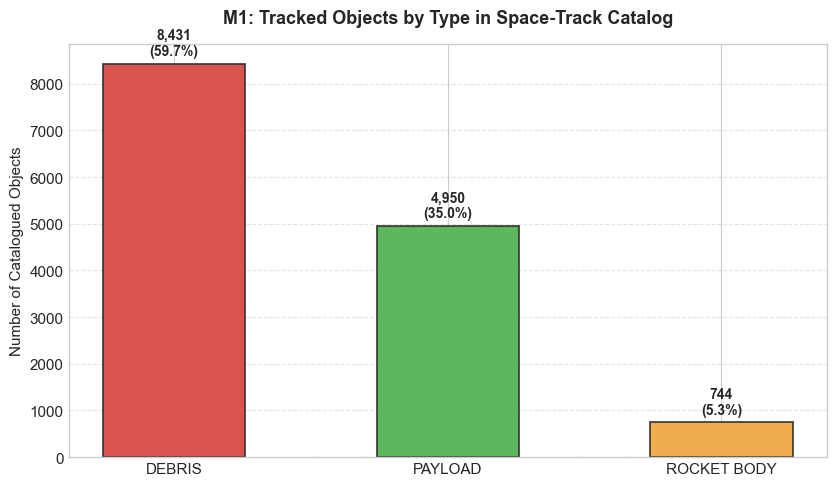

In [3]:
# M1: Bar Chart — Objects by Type
fig, ax = plt.subplots(figsize=(8.5, 5), dpi=100)
type_counts = df['OBJECT_TYPE'].value_counts()
colors = ['#d9534f', '#5cb85c', '#f0ad4e']

bars = ax.bar(type_counts.index, type_counts.values, color=colors, edgecolor='#333333', linewidth=1.2, width=0.52)
ax.set_title("M1: Tracked Objects by Type in Space-Track Catalog", fontsize=13, fontweight='bold', pad=15)
ax.set_ylabel("Number of Catalogued Objects", fontsize=11)
ax.grid(axis='y', linestyle='--', alpha=0.5)

# Value labels above bars
for bar in bars:
    height = bar.get_height()
    pct = (height / len(df)) * 100
    ax.annotate(f"{height:,}\n({pct:.1f}%)",
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 4), textcoords="offset points",
                ha='center', va='bottom', fontsize=10, fontweight='semibold')

plt.tight_layout()
plt.show()

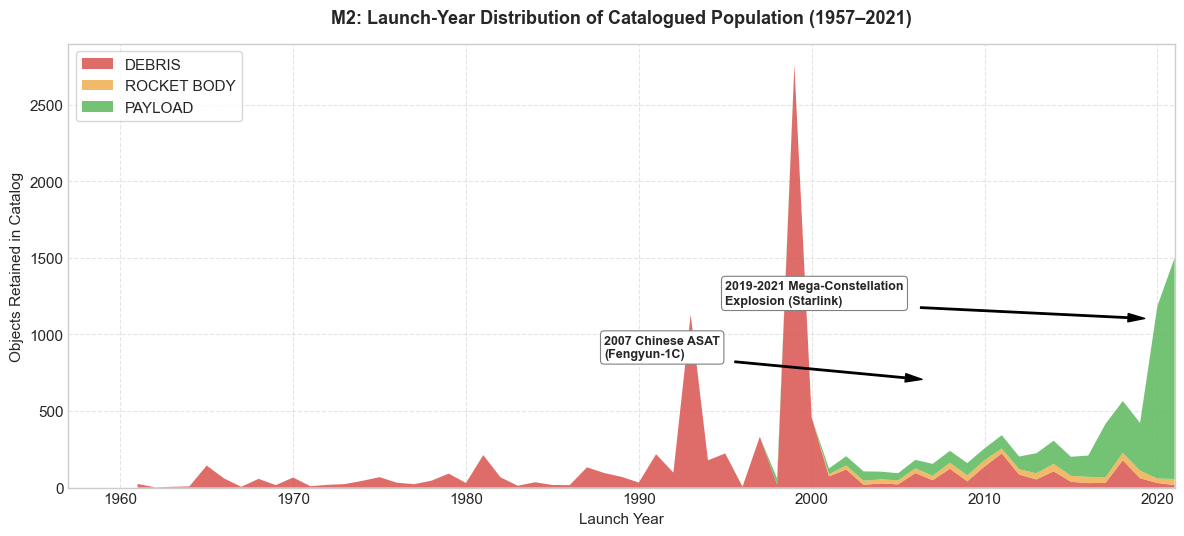

In [4]:
# M2: Stacked Area Chart — Launch-Year Distribution (1957–2021)
fig, ax = plt.subplots(figsize=(12, 5.5), dpi=100)

yearly = df[(df['LAUNCH_YEAR'] >= 1957) & (df['LAUNCH_YEAR'] <= 2021)]
yearly_pivot = yearly.groupby(['LAUNCH_YEAR', 'OBJECT_TYPE']).size().unstack(fill_value=0)

years = yearly_pivot.index
debris = yearly_pivot.get('DEBRIS', pd.Series(0, index=years))
rb = yearly_pivot.get('ROCKET BODY', pd.Series(0, index=years))
payload = yearly_pivot.get('PAYLOAD', pd.Series(0, index=years))

ax.stackplot(years, [debris, rb, payload], labels=['DEBRIS', 'ROCKET BODY', 'PAYLOAD'],
             colors=['#d9534f', '#f0ad4e', '#5cb85c'], alpha=0.85)

ax.set_title("M2: Launch-Year Distribution of Catalogued Population (1957–2021)", fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel("Launch Year", fontsize=11)
ax.set_ylabel("Objects Retained in Catalog", fontsize=11)
ax.set_xlim(1957, 2021)
ax.legend(loc='upper left', frameon=True)
ax.grid(True, linestyle='--', alpha=0.5)

# Historical annotations
ax.annotate('2007 Chinese ASAT\n(Fengyun-1C)', xy=(2007, 700), xytext=(1988, 850),
            arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=6),
            fontsize=9, fontweight='semibold', bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", lw=0.8))

ax.annotate('2019-2021 Mega-Constellation\nExplosion (Starlink)', xy=(2020, 1100), xytext=(1995, 1200),
            arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=6),
            fontsize=9, fontweight='semibold', bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", lw=0.8))

plt.tight_layout()
plt.show()

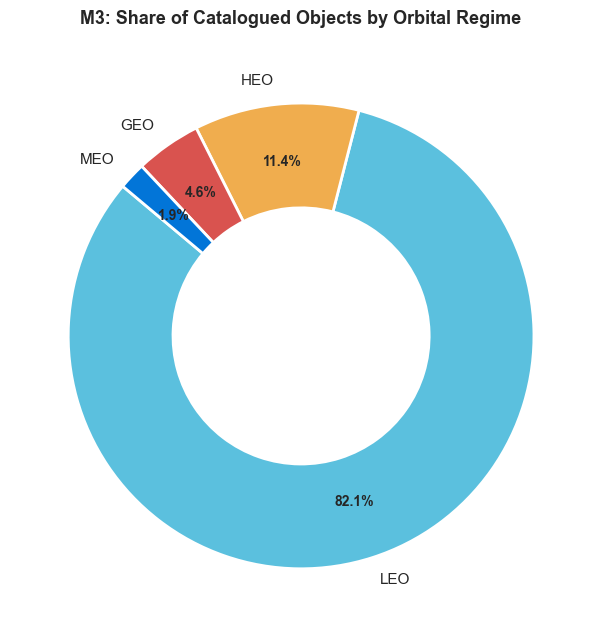

In [5]:
# M3: Donut Chart — Share by Orbital Regime
fig, ax = plt.subplots(figsize=(6.5, 6.5), dpi=100)
orbit_counts = df['ORBIT_CLASS'].value_counts()
orbit_colors = ['#5bc0de', '#f0ad4e', '#d9534f', '#0275d8']

wedges, texts, autotexts = ax.pie(
    orbit_counts.values,
    labels=orbit_counts.index,
    autopct='%1.1f%%',
    pctdistance=0.75,
    colors=orbit_colors,
    startangle=140,
    wedgeprops=dict(width=0.45, edgecolor='white', linewidth=2)
)

for autotext in autotexts:
    autotext.set_fontsize(10)
    autotext.set_fontweight('bold')

ax.set_title("M3: Share of Catalogued Objects by Orbital Regime", fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

## 4. Seaborn Statistical Visualizations (Tool 2)
Executing visualizations **S1**, **S2**, **S3**, **S4**, and **S5** as specified in the Primary Review.
- **S1:** Inclination Distribution Histogram / KDE
- **S2:** Orbital Period by Object Type (Violin Plot, Log Scale)
- **S3:** Orbital Regime Map (Log-Log Scatter of Apoapsis vs. Periapsis)
- **S4:** Correlation Heatmap of Orbital Elements
- **S5:** Top 10 Country / Organization Codes (Lollipop / Pareto Chart)


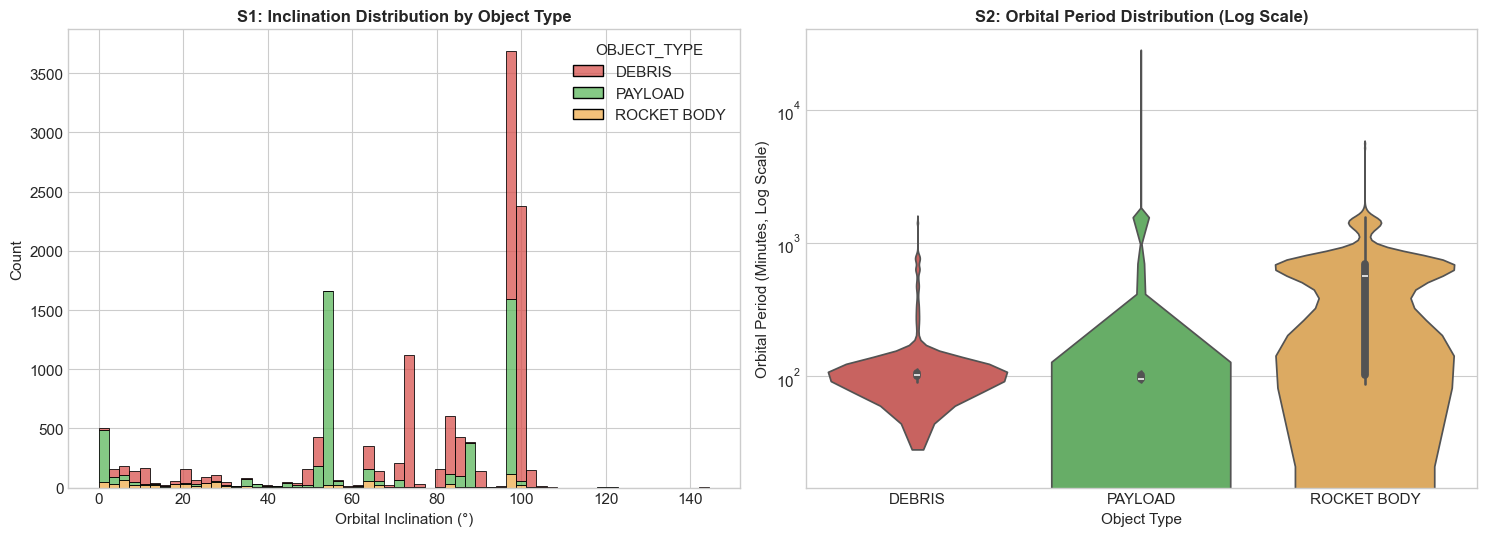

In [6]:
# S1 & S2: Inclination Distribution & Orbital Period Violin
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5), dpi=100)

# S1: Histogram
sns.histplot(data=df, x='INCLINATION', hue='OBJECT_TYPE', multiple='stack',
             palette={'DEBRIS': '#d9534f', 'PAYLOAD': '#5cb85c', 'ROCKET BODY': '#f0ad4e'},
             bins=60, ax=ax1)
ax1.set_title("S1: Inclination Distribution by Object Type", fontsize=12, fontweight='bold')
ax1.set_xlabel("Orbital Inclination (°)")
ax1.set_ylabel("Count")

# S2: Violin Plot (Log Scale)
sns.violinplot(data=df, x='OBJECT_TYPE', y='PERIOD', palette=['#d9534f', '#5cb85c', '#f0ad4e'], ax=ax2)
ax2.set_yscale('log')
ax2.set_title("S2: Orbital Period Distribution (Log Scale)", fontsize=12, fontweight='bold')
ax2.set_xlabel("Object Type")
ax2.set_ylabel("Orbital Period (Minutes, Log Scale)")

plt.tight_layout()
plt.show()

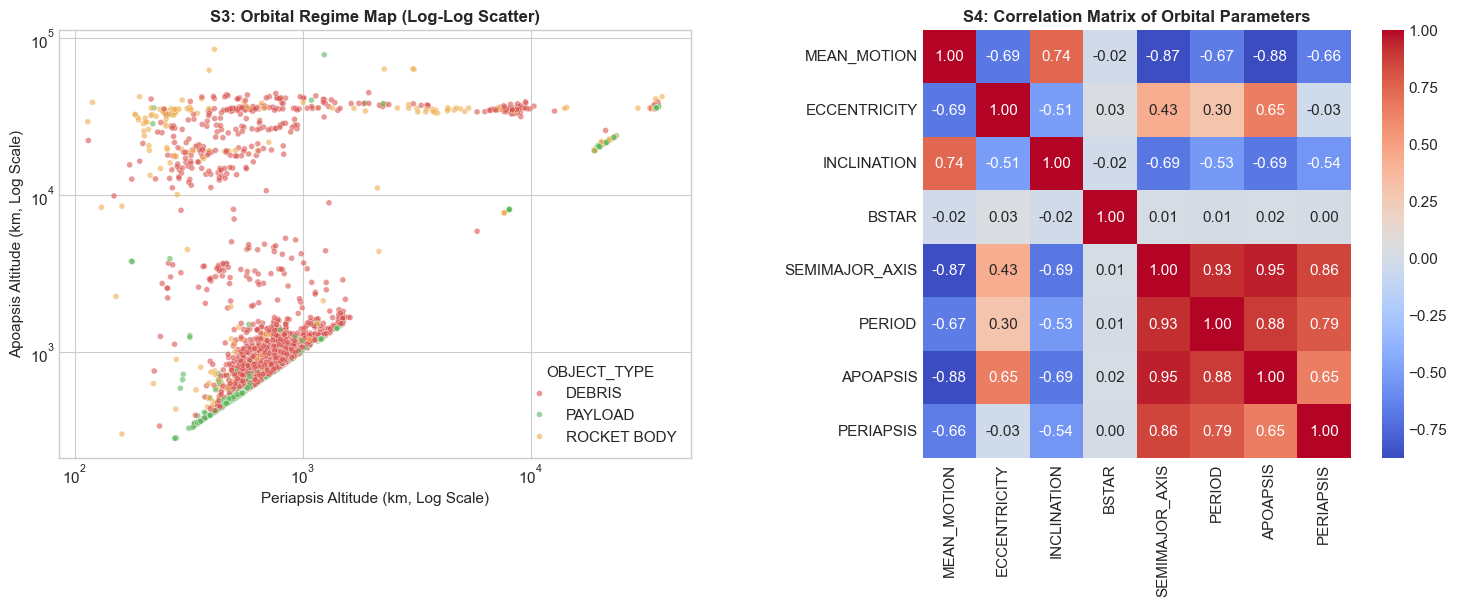

In [7]:
# S3 & S4: Regime Scatter Map and Correlation Heatmap
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), dpi=100)

# S3: Apoapsis vs Periapsis (Log-Log Scatter)
sample_scatter = df.sample(min(len(df), 5000), random_state=42)
sns.scatterplot(data=sample_scatter, x='PERIAPSIS', y='APOAPSIS', hue='OBJECT_TYPE',
                palette={'DEBRIS': '#d9534f', 'PAYLOAD': '#5cb85c', 'ROCKET BODY': '#f0ad4e'},
                alpha=0.6, s=18, ax=ax1)
ax1.set_xscale('log')
ax1.set_yscale('log')
ax1.set_title("S3: Orbital Regime Map (Log-Log Scatter)", fontsize=12, fontweight='bold')
ax1.set_xlabel("Periapsis Altitude (km, Log Scale)")
ax1.set_ylabel("Apoapsis Altitude (km, Log Scale)")

# S4: Correlation Heatmap of Numeric Parameters
corr_cols = ['MEAN_MOTION', 'ECCENTRICITY', 'INCLINATION', 'BSTAR', 'SEMIMAJOR_AXIS', 'PERIOD', 'APOAPSIS', 'PERIAPSIS']
corr_matrix = df[corr_cols].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', cbar=True, ax=ax2, square=True)
ax2.set_title("S4: Correlation Matrix of Orbital Parameters", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

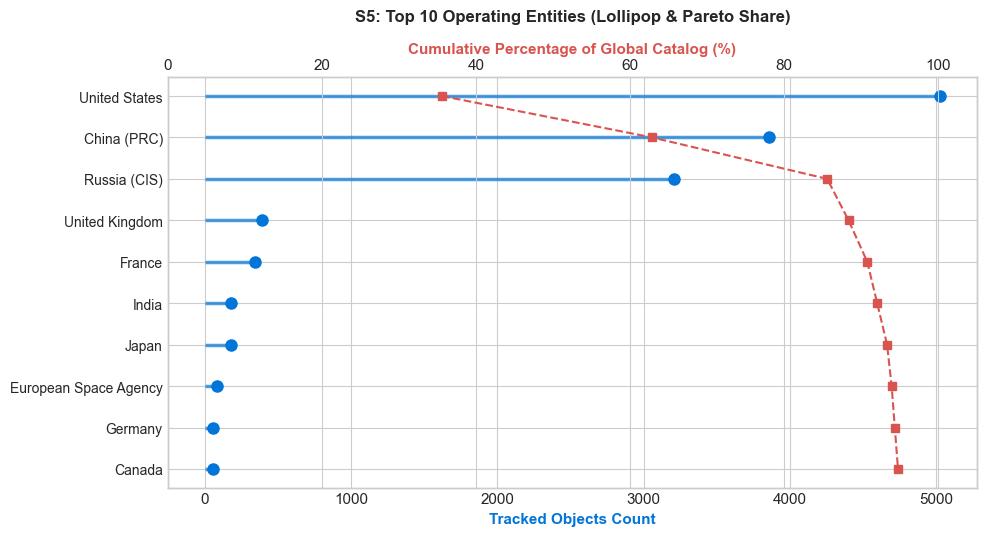

In [8]:
# S5: Top 10 Countries Pareto / Lollipop Chart
fig, ax1 = plt.subplots(figsize=(10, 5.5), dpi=100)

top_countries = df['COUNTRY_NAME'].value_counts().head(10)
cum_pct = (top_countries.cumsum() / len(df)) * 100

y_pos = range(len(top_countries))
ax1.hlines(y=y_pos, xmin=0, xmax=top_countries.values, color='#0275d8', alpha=0.7, linewidth=2.5)
ax1.plot(top_countries.values, y_pos, "o", markersize=8, color='#0275d8')

ax1.set_yticks(y_pos)
ax1.set_yticklabels(top_countries.index, fontsize=10)
ax1.invert_yaxis()
ax1.set_xlabel("Tracked Objects Count", color='#0275d8', fontweight='bold')
ax1.set_title("S5: Top 10 Operating Entities (Lollipop & Pareto Share)", fontsize=12, fontweight='bold', pad=15)

# Secondary axis for cumulative percentage
ax2 = ax1.twiny()
ax2.plot(cum_pct.values, y_pos, color='#d9534f', linestyle='--', marker='s', markersize=6)
ax2.set_xlabel("Cumulative Percentage of Global Catalog (%)", color='#d9534f', fontweight='bold')
ax2.set_xlim(0, 105)

plt.tight_layout()
plt.show()

## 5. Interactive Plotly Visualizations (Tool 3)
Executing strictly the two planned Plotly interactive figures as specified in Section 9 of the Primary Review report:
- **P1:** Interactive Inclination vs. Mean Altitude Scatter Plot (with hover tooltips and orbital regime callouts)
- **P2:** Interactive Population Hierarchy Treemap (Drill-down by `OBJECT_TYPE` → `COUNTRY_NAME` → `RCS_SIZE`)


In [9]:
# P1: Interactive Scatter Plot — Inclination vs. Mean Altitude
plot_df = df[df['MEAN_ALTITUDE_KM'] <= 42000].copy()

fig_p1 = px.scatter(
    plot_df,
    x='INCLINATION',
    y='MEAN_ALTITUDE_KM',
    color='OBJECT_TYPE',
    symbol='RCS_SIZE',
    symbol_map={'SMALL': 'circle', 'MEDIUM': 'diamond', 'LARGE': 'square', 'UNKNOWN': 'cross'},
    color_discrete_map={'DEBRIS': '#FF4B4B', 'PAYLOAD': '#00D26A', 'ROCKET BODY': '#FFAA00'},
    hover_name='OBJECT_NAME',
    hover_data={
        'NORAD_CAT_ID': True,
        'COUNTRY_NAME': True,
        'LAUNCH_YEAR': True,
        'ORBIT_CLASS': True,
        'APOAPSIS': ':.1f',
        'PERIAPSIS': ':.1f',
        'INCLINATION': ':.2f',
        'MEAN_ALTITUDE_KM': ':.1f',
        'OBJECT_TYPE': False,
        'RCS_SIZE': True
    },
    title="<b>P1: Interactive Orbital Regime Map — Inclination vs. Mean Altitude</b>",
    labels={'INCLINATION': 'Inclination (°)', 'MEAN_ALTITUDE_KM': 'Mean Altitude (km)', 'OBJECT_TYPE': 'Object Type'},
    opacity=0.72
)

# Reference orbital boundaries
fig_p1.add_hline(y=35786, line_dash="dash", line_color="#EC4899",
                 annotation_text="GEO Ring (35,786 km)", annotation_position="top left")
fig_p1.add_hline(y=2000, line_dash="dot", line_color="#00E5FF",
                 annotation_text="LEO Upper Limit (2,000 km)", annotation_position="bottom left")

fig_p1.update_layout(
    template="plotly_dark",
    height=620,
    legend=dict(orientation="v", y=0.5, x=1.02, xanchor="left", title=dict(text="<b>Type & Size</b>"))
)
fig_p1.show()

In [10]:
# P2: Interactive Treemap — Hierarchy of Catalog (Object Type → Country → Size)
top_ctry = df['COUNTRY_NAME'].value_counts().head(10).index.tolist()
tree_df = df.copy()
tree_df['COUNTRY_GROUP'] = tree_df['COUNTRY_NAME'].apply(lambda c: c if c in top_ctry else 'Other Nations')
agg_tree = tree_df.groupby(['OBJECT_TYPE', 'COUNTRY_GROUP', 'RCS_SIZE']).size().reset_index(name='COUNT')

fig_p2 = px.treemap(
    agg_tree,
    path=['OBJECT_TYPE', 'COUNTRY_GROUP', 'RCS_SIZE'],
    values='COUNT',
    color='OBJECT_TYPE',
    color_discrete_map={'DEBRIS': '#FF4B4B', 'PAYLOAD': '#00D26A', 'ROCKET BODY': '#FFAA00'},
    title="<b>P2: Catalog Population Hierarchy — Object Type → Country → Radar Cross Section</b>"
)
fig_p2.update_traces(
    textinfo="label+value+percent parent",
    hovertemplate="<b>%{label}</b><br>Tracked Objects: %{value:,}<br>Share of Parent: %{percentParent:.1%}<br>Share of Total: %{percentRoot:.1%}<extra></extra>"
)
fig_p2.update_layout(template="plotly_dark", height=600)
fig_p2.show()

## 6. Ethical Visualization Case Study (Course Rubric Requirement)
### Intentionally Misleading Visualization vs. Ethical Redesign
Under the course assignment rubric, students must demonstrate ethical visual communication by producing an intentionally misleading visualization and its principled redesign.

#### The Misleading Technique: Truncated Y-Axis
- **Distortion:** Setting the vertical axis baseline to 3,000 rather than 0.
- **Deception:** The visual bar height of the United States (5,026 - 3,000 = 2,026 px) appears almost **10 times taller** than Russia (3,207 - 3,000 = 207 px), creating an extreme visual illusion that the US is generating unprecedentedly massive debris volumes compared to its peers.
- **The True Reality:** Mathematically, the US has only **1.56 times** as many objects as Russia.
- **Tufte Lie Factor:**  
  $$\text{Lie Factor} = \frac{\text{Size of effect shown in graphic}}{\text{Size of effect in data}} = \frac{(2026/207)}{(5026/3207)} = \frac{9.78}{1.56} \approx 6.27$$
  A Lie Factor of 6.27 represents severe, unethical distortion (> 1.05 indicates distortion).


In [11]:
# Ethical Case Study: Side-by-Side Misleading vs. Ethical Redesign
top3_data = pd.DataFrame({
    'Country': ['United States', 'China (PRC)', 'Russia (CIS)'],
    'Objects': [5026, 3853, 3207]
})

fig_ethics = make_subplots(
    rows=1, cols=2,
    subplot_titles=(
        "⚠️ <b>MISLEADING</b><br><span style='font-size:11px;color:#FF8080;'>Truncated Axis (Base 3,000)</span>",
        "✅ <b>ETHICAL REDESIGN</b><br><span style='font-size:11px;color:#80FFB0;'>Accurate Scale (Base 0)</span>"
    ),
    horizontal_spacing=0.22
)

# Misleading Bar
fig_ethics.add_trace(
    go.Bar(x=top3_data['Country'], y=top3_data['Objects'],
           marker_color=['#FF4B4B', '#FF7A00', '#FFAA00'],
           text=[f"{v:,}" for v in top3_data['Objects']], textposition='outside', showlegend=False),
    row=1, col=1
)

# Ethical Bar
fig_ethics.add_trace(
    go.Bar(x=top3_data['Country'], y=top3_data['Objects'],
           marker_color=['#00D26A', '#00B4D8', '#48CAE4'],
           text=[f"{v:,} ({v/top3_data['Objects'].sum():.1%})" for v in top3_data['Objects']],
           textposition='outside', showlegend=False),
    row=1, col=2
)

fig_ethics.update_yaxes(title_text="Tracked Objects (Truncated Base: 3,000)", range=[3000, 5300], row=1, col=1)
fig_ethics.update_yaxes(title_text="Tracked Objects (Honest Base: 0)", range=[0, 5800], row=1, col=2)
fig_ethics.update_layout(
    template="plotly_dark",
    height=540,
    margin=dict(t=100, b=50, l=60, r=60),
    title=dict(text="<b>Ethical Visualization Lab — Deceptive vs. Honest Scaling</b>", font=dict(size=14)),
    font=dict(family="Arial, sans-serif")
)
for a in fig_ethics['layout']['annotations']:
    if 'MISLEADING' in a['text'] or 'ETHICAL' in a['text']:
        a['font'] = dict(size=12)
fig_ethics.show()

## 7. Analytical Insights & Space Traffic Management (STM) Conclusion
1. **Catalog Composition:** Space debris constitutes **59.7%** (8,431 items) of the entire catalogued population. Combined with derelict rocket bodies (5.3%), defunct orbital hardware comprises over **65% of all tracked objects**.
2. **Orbital Shell Congestion:** Low Earth Orbit (LEO, altitude < 2,000 km) houses **82.1%** of all tracked space assets and debris. Within LEO, Sun-Synchronous Orbits (~98° inclination) represent the most hazardous conjunction hot-spots.
3. **Attribution Concentration:** Over **85%** of all catalogued items belong to three entities: the United States, China, and Russia. International space sustainability treaties must prioritize active debris remediation (ADR) among these primary actors.
4. **Interactive Dashboard:** The two interactive figures (**P1** and **P2**) are deployed in `plotly_app.py`, creating a unified local dashboard for live evaluation.
